# Visualizing subgroups

`pysubgroup.visualization` implements visualizations proposed
in the subgroup discovery literature (see `user_guide/11-results-and-visualization.md` for
details and references). Each function takes search results, the data, and the
fitted target, and returns a matplotlib `Axes`.

Requirements: `pip install pysubgroup[plot] scikit-learn`.

In [1]:
from sklearn.datasets import fetch_openml

# Adult / Census Income (OpenML dataset 1590): 48,842 people, income above 50K or not.
adult = fetch_openml("adult", version=2, as_frame=True)
# fnlwgt is a census sampling weight, not a property of the person.
data = adult.frame.drop(columns=["fnlwgt"])
features = data.drop(columns="class")
data.head()

,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [2]:
import pysubgroup as sd
from pysubgroup import generate_conditions
from pysubgroup import visualization as viz

conditions = generate_conditions(features, n_bins=5)
target = sd.BinaryTarget().fit(data, "class", ">50K")
task = sd.SubgroupDiscoveryTask(
    data, target, conditions, sd.WRAccQF(), result_set_size=8, depth=2,
    filters=[sd.MinSizeFilter(0.02)],
)
results = sd.DFS().execute(task)
for number, (quality, rule) in enumerate(results, start=1):
    print(f"#{number}  {quality:.4f}  {viz.rule_label(rule)}")

#1  0.0948  marital-status=Married-civ-spouse
#2  0.0892  marital-status=Married-civ-spouse ∧ native-country=United-States
#3  0.0881  marital-status=Married-civ-spouse ∧ race=White
#4  0.0845  relationship=Husband ∧ sex=Male
#5  0.0845  relationship=Husband
#6  0.0845  marital-status=Married-civ-spouse ∧ relationship=Husband
#7  0.0842  marital-status=Married-civ-spouse ∧ sex=Male
#8  0.0817  marital-status=Married-civ-spouse ∧ capital-loss ∈ (-∞, 1485]


## Size and target share of each subgroup

**Bar visualization** (Kralj, Lavrač, Zupan 2005): the first row shows the whole
dataset; each further row a subgroup, sorted by target share. Positives extend
to the right, negatives to the left, so both size and composition are visible.

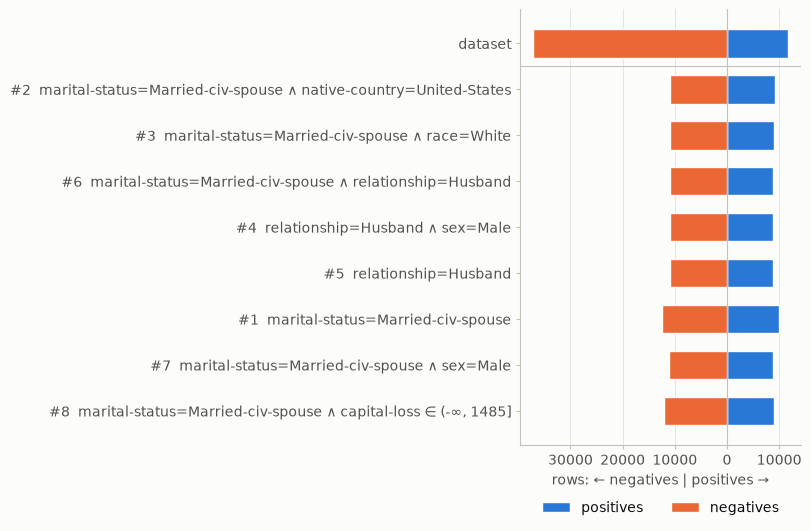

In [3]:
viz.plot_subgroup_bars(results, data, target);

**Spineplot** (VIKAMINE's stacked bars; Atzmueller and Puppe 2005): bar width is
the subgroup size, the blue part its target share, and the line the overall
share. Subgroups are numbered in result order.

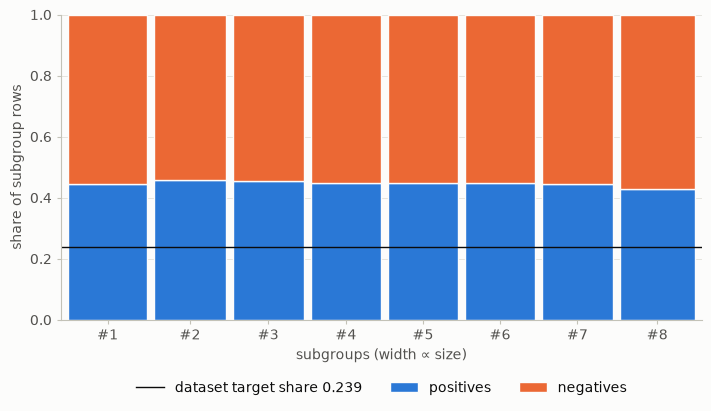

In [4]:
viz.plot_spineplot(results, data, target);

## Comparing subgroups in ROC space

Each subgroup is a point of its false and true positive rates (Lavrač et al.
2004). Points on the diagonal have the same class distribution as the dataset;
the convex hull connects the potentially optimal subgroups. The gray contour
lines are **isometrics** of WRAcc (Fürnkranz and Flach 2005): subgroups on the
same line have the same quality.

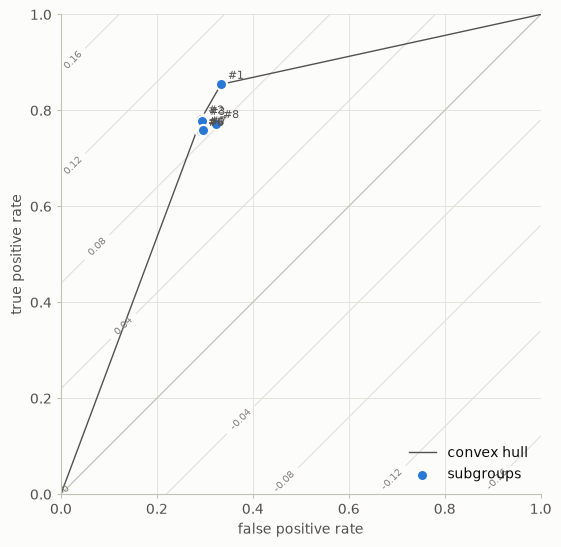

In [5]:
viz.plot_roc_space(results, data, target, isometrics=sd.WRAccQF());

With `counts=True` the same view uses absolute counts (coverage space), here with
the isometrics of the binomial quality function `StandardQF(0.5)`, which bend
towards smaller subgroups.

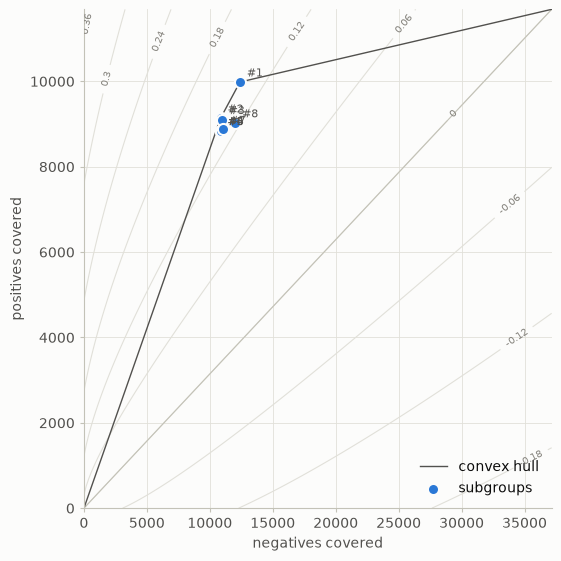

In [6]:
viz.plot_roc_space(results, data, target, counts=True, isometrics=sd.StandardQF(0.5));

**Size versus effect** (as in Slice Finder, Chung et al. 2019): subgroup size
against target share, with the dataset share as reference.

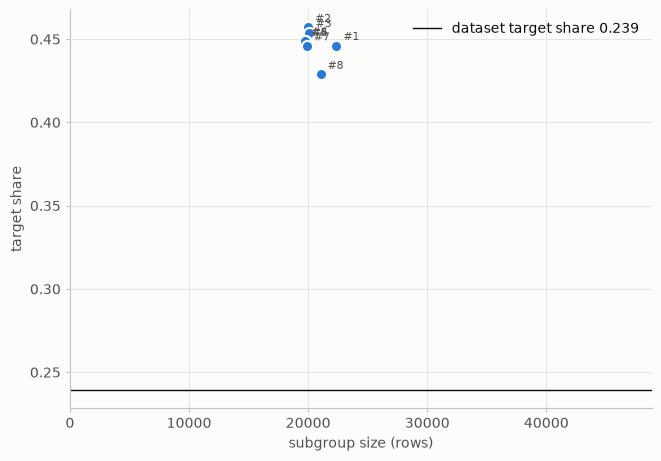

In [7]:
viz.plot_size_quality(results, data, target, y="target_share");

## Distributions within subgroups

**Distribution over a numeric attribute** (Gamberger, Lavrač, Wettschereck 2002):
positives above and negatives below the axis, here over `age`. The shaded area
is the dataset, each line a subgroup.

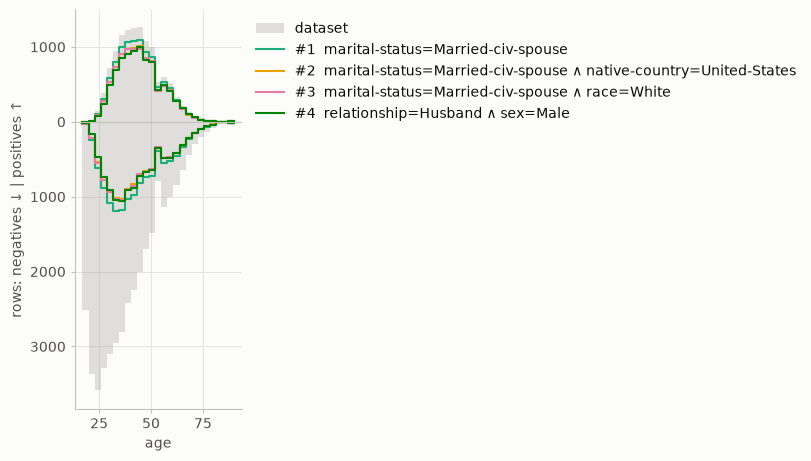

In [8]:
viz.plot_attribute_distribution(results[:4], data, target, "age", bins=25);

For **numeric targets**, box plots compare the target distribution of each
subgroup with the dataset (distribution rules; Jorge et al. 2006). Here: groups
with unusually long working hours.

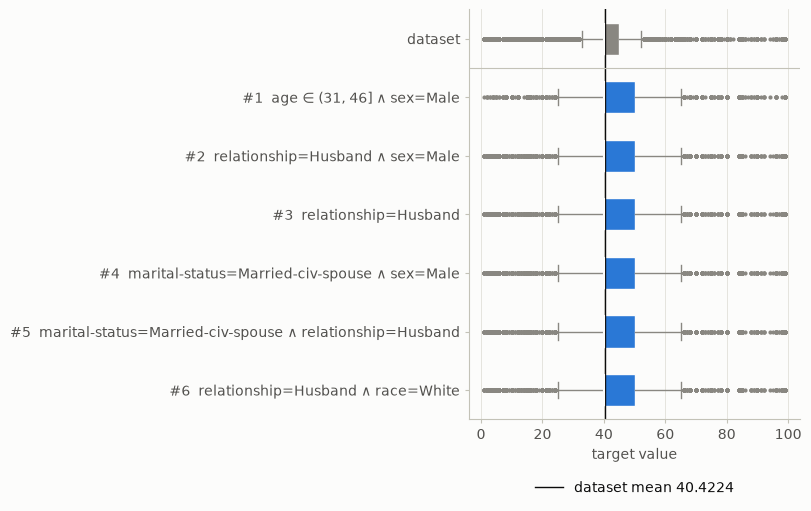

In [9]:
hours = sd.NumericTarget().fit(data, "hours-per-week")
hour_results = sd.DFS().execute(sd.SubgroupDiscoveryTask(
    data, hours, conditions, sd.StandardQFNumeric(0.5), result_set_size=6, depth=2,
    filters=[sd.MinSizeFilter(200)],
))
viz.plot_target_distributions(hour_results, data, hours);

## Relations between subgroups

Top-k results are often redundant. The **overlap view** (VIKAMINE) shows the
covered rows of each subgroup, colored by class, with similar subgroups next to
each other (complete-linkage clustering on Jaccard similarity).

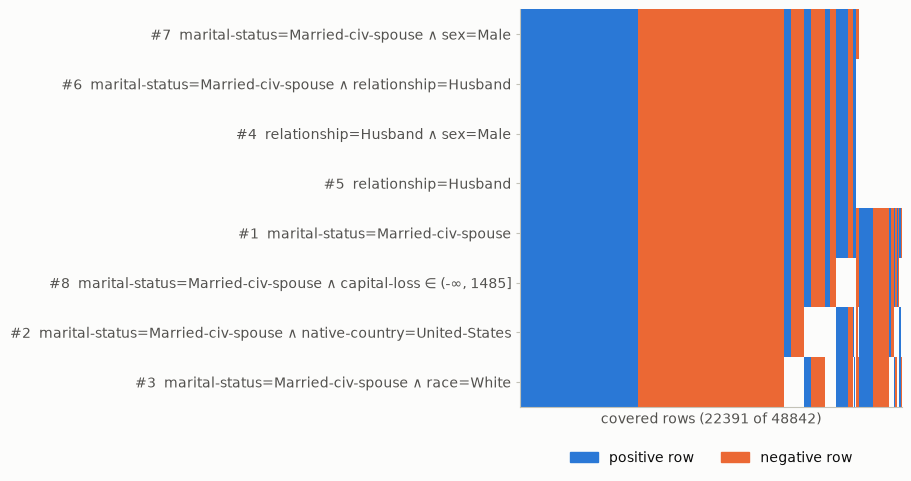

In [10]:
viz.plot_overlap(results, data, target);

The **similarity matrix** quantifies the overlap as Jaccard similarity of the
covered rows.

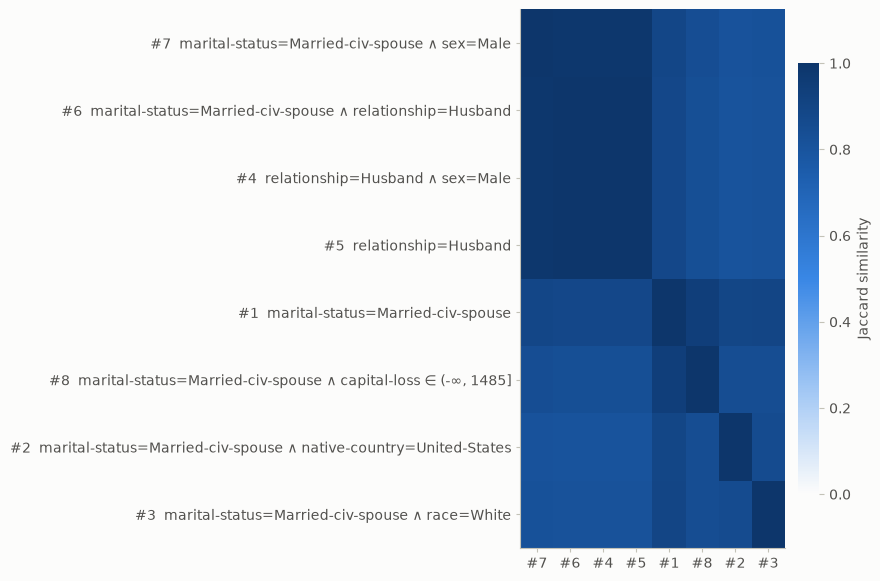

In [11]:
viz.plot_similarity(results, data);

The **similarity dendrogram** shows the hierarchical clustering behind this
order: subgroups that cover almost the same rows join close to Jaccard
distance 0 and are candidates for removal.

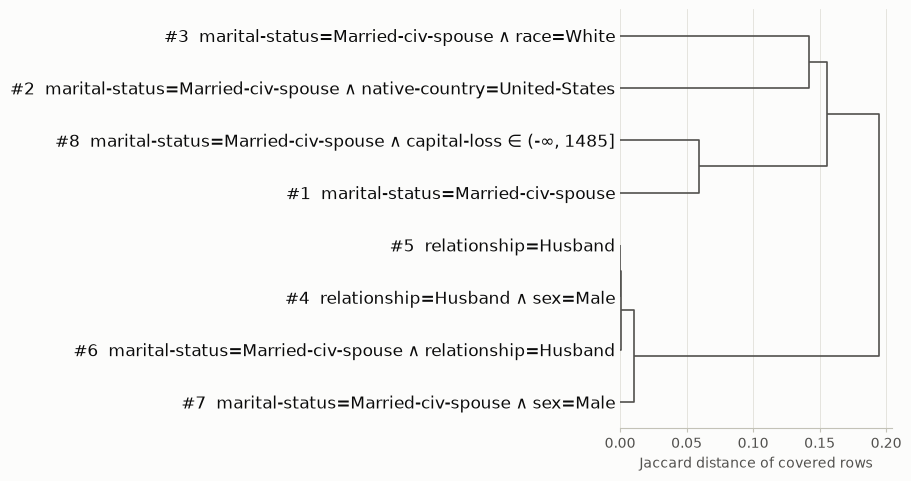

In [12]:
viz.plot_similarity_dendrogram(results, data);

The **specialization graph** (VIKAMINE) arranges subgroups by the number of
conditions and connects each to its direct specializations. Each node shows
positives and negatives; darker positive parts indicate higher quality.

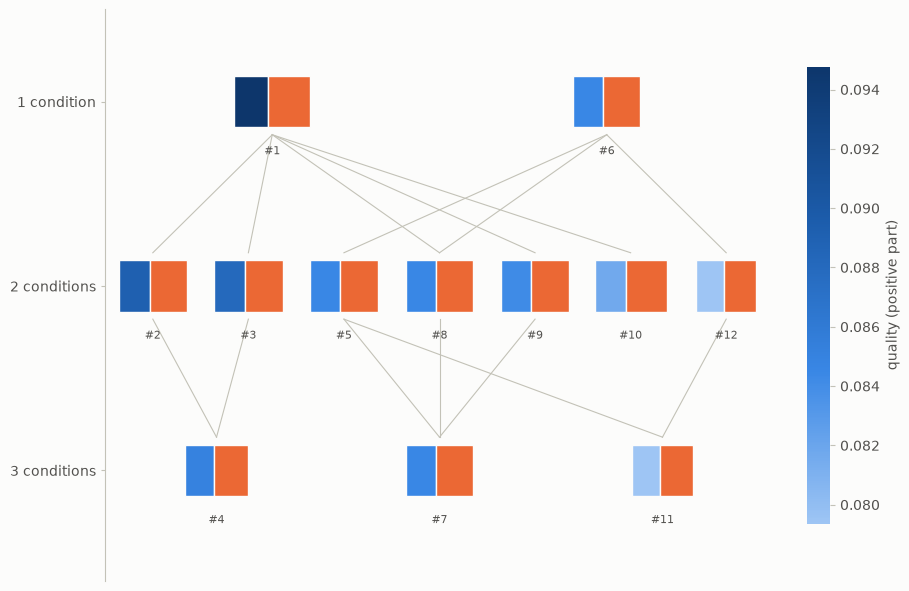

In [13]:
deeper = sd.DFS().execute(sd.SubgroupDiscoveryTask(
    data, target, conditions, sd.WRAccQF(), result_set_size=12, depth=3,
    filters=[sd.MinSizeFilter(0.02)],
))
viz.plot_specialization_graph(deeper, data, target);

## Dark theme

All functions accept `theme="dark"` and draw onto existing axes via `ax=`, so
they can be combined into larger figures.

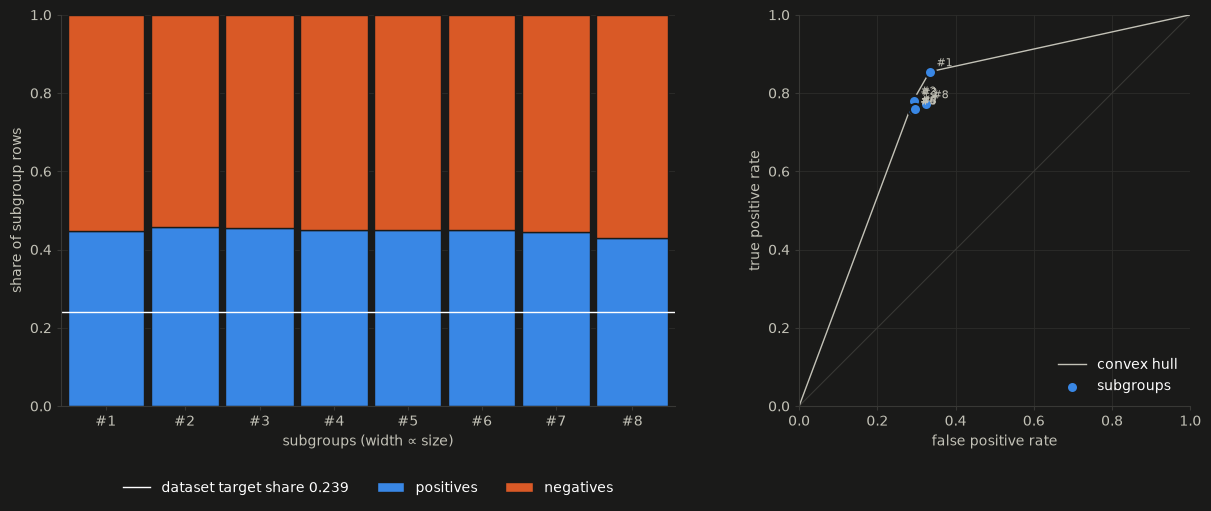

In [14]:
import matplotlib.pyplot as plt

figure, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
viz.plot_spineplot(results, data, target, ax=axes[0], theme="dark")
viz.plot_roc_space(results, data, target, ax=axes[1], theme="dark")
plt.show()